# Module 01b: Seaborn Statistical Visualization

## Learning Objectives

By the end of this notebook, you will be able to:
- Understand why Seaborn is preferred for statistical visualization
- Create distribution plots (histogram, KDE, box, violin)
- Create categorical plots (count, bar, swarm, strip)
- Create relationship plots (scatter, regression, heatmap)
- Use multi-plot grids (FacetGrid, pairplot)
- Interpret statistical visualizations correctly

**Prerequisites:** Python basics, Matplotlib fundamentals (01a)

---

## 1. Why Seaborn?

**Seaborn** is built on top of Matplotlib and provides:

| Feature | Matplotlib | Seaborn |
|---------|------------|----------|
| Default appearance | Plain | Beautiful |
| Statistical plots | Manual | Built-in |
| Pandas integration | Good | Excellent |
| Code required | More | Less |

**Bottom line:** Use Seaborn for statistical visualization, Matplotlib for fine-tuning.

In [1]:
# Import libraries
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Set Seaborn style
sns.set_style("whitegrid")
sns.set_context("notebook")

# Load sample datasets
tips = sns.load_dataset('tips')
iris = sns.load_dataset('iris')

print("Seaborn version:", sns.__version__)
print("\nTips dataset shape:", tips.shape)
print("Iris dataset shape:", iris.shape)

Seaborn version: 0.13.2

Tips dataset shape: (244, 7)
Iris dataset shape: (150, 5)


In [2]:
# Preview the tips dataset
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### Matplotlib vs Seaborn: Same Plot, Different Code

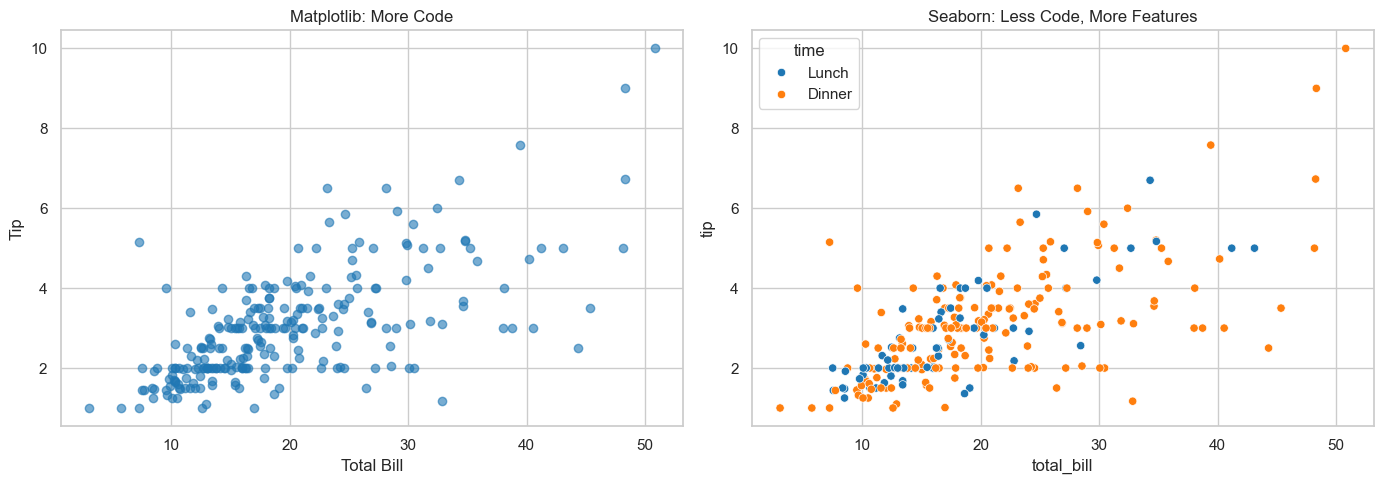

In [3]:
# Matplotlib: More code, plain appearance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matplotlib scatter plot
axes[0].scatter(tips['total_bill'], tips['tip'], alpha=0.6)
axes[0].set_xlabel('Total Bill')
axes[0].set_ylabel('Tip')
axes[0].set_title('Matplotlib: More Code')

# Seaborn scatter plot
sns.scatterplot(data=tips, x='total_bill', y='tip', hue='time', ax=axes[1])
axes[1].set_title('Seaborn: Less Code, More Features')

plt.tight_layout()
plt.show()

---

## 2. Distribution Plots

**Purpose:** Understand how values of a single variable are distributed.

### 2.1 Histogram with KDE

**When to use:** See the shape of a distribution.

**KDE (Kernel Density Estimation):** A smooth curve showing the distribution shape.

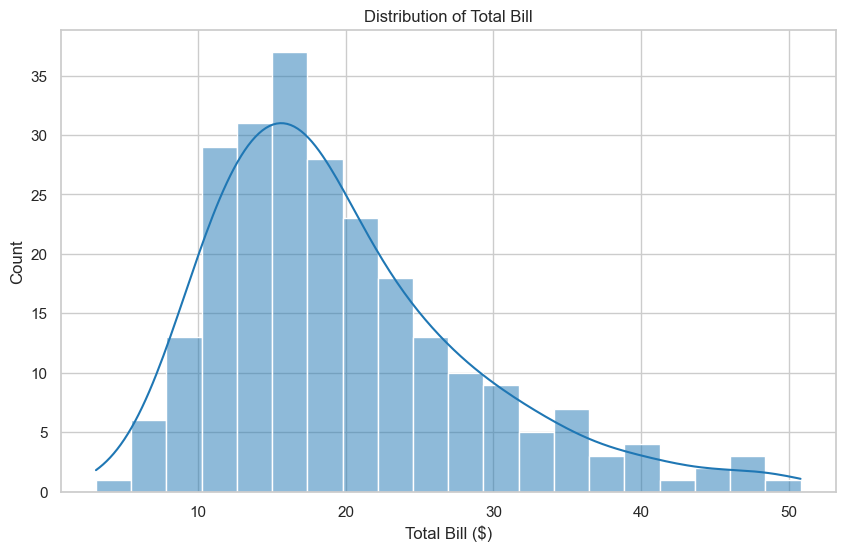

In [4]:
# Histogram with KDE
plt.figure(figsize=(10, 6))
sns.histplot(data=tips, x='total_bill', kde=True, bins=20)

plt.title('Distribution of Total Bill')
plt.xlabel('Total Bill ($)')
plt.ylabel('Count')

plt.show()

### Comparing Distributions by Category

Use `hue` to split by a categorical variable.

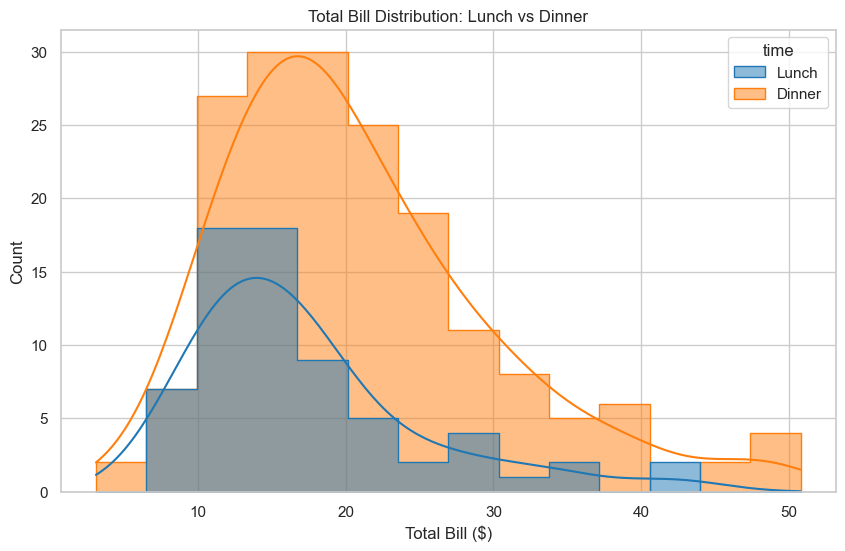

In [5]:
# Compare distributions by time of day
plt.figure(figsize=(10, 6))
sns.histplot(data=tips, x='total_bill', hue='time', kde=True, 
             element='step', alpha=0.5)

plt.title('Total Bill Distribution: Lunch vs Dinner')
plt.xlabel('Total Bill ($)')

plt.show()

### 2.2 Box Plots

**When to use:** Compare distributions across categories and identify outliers.

**How to read a box plot:**
- **Box:** Middle 50% of data (IQR = Q3 - Q1)
- **Line inside box:** Median (50th percentile)
- **Whiskers:** Extend to 1.5 * IQR
- **Dots beyond whiskers:** Outliers

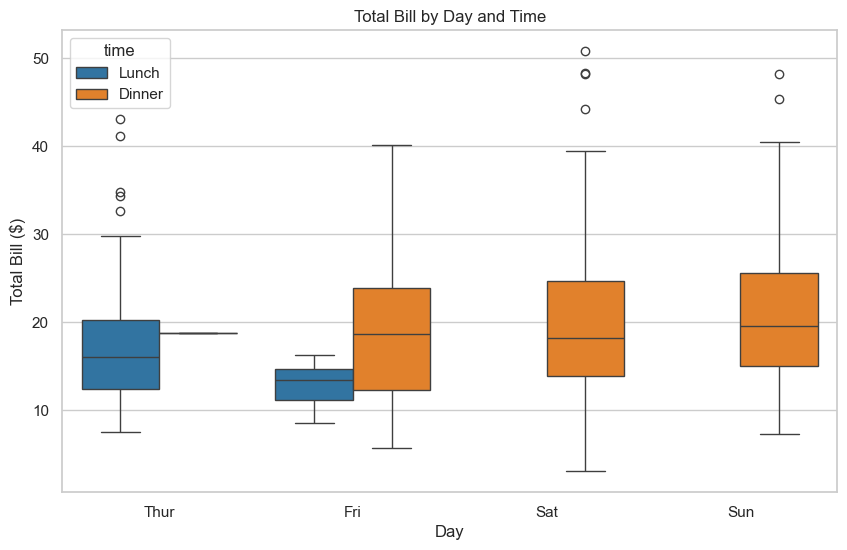

In [6]:
# Box plot
plt.figure(figsize=(10, 6))
sns.boxplot(data=tips, x='day', y='total_bill', hue='time')

plt.title('Total Bill by Day and Time')
plt.xlabel('Day')
plt.ylabel('Total Bill ($)')

plt.show()

### How to Interpret Box Plots

| Feature | What It Tells You |
|---------|-------------------|
| **Box height (IQR)** | Spread of middle 50% |
| **Median line position** | Typical value |
| **Median near top/bottom** | Data is skewed |
| **Long whisker one side** | Tail in that direction |
| **Many dots (outliers)** | Unusual values to investigate |

### 2.3 Violin Plots

**When to use:** See the full distribution shape + box plot statistics.

**Like a box plot, but shows the density curve on both sides.**

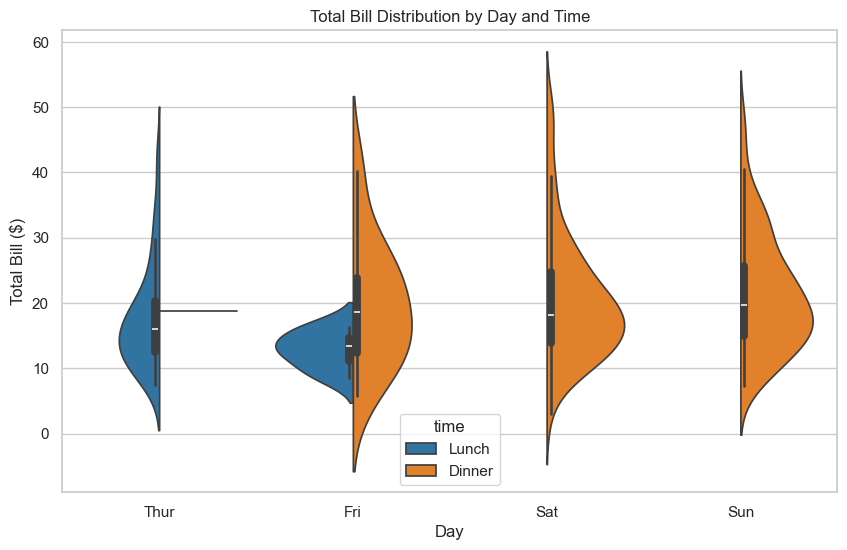

In [7]:
# Violin plot
plt.figure(figsize=(10, 6))
sns.violinplot(data=tips, x='day', y='total_bill', hue='time', split=True)

plt.title('Total Bill Distribution by Day and Time')
plt.xlabel('Day')
plt.ylabel('Total Bill ($)')

plt.show()

### Box vs Violin: When to Use Which

| Use Box Plot When | Use Violin Plot When |
|-------------------|----------------------|
| You mainly care about outliers | You want to see the full shape |
| You have many categories | You have few categories |
| Audience is technical | Distribution shape matters |

---

## 3. Categorical Plots

**Purpose:** Visualize data grouped by categories.

### 3.1 Count Plot

**When to use:** Count occurrences in each category (like a bar chart for counts).

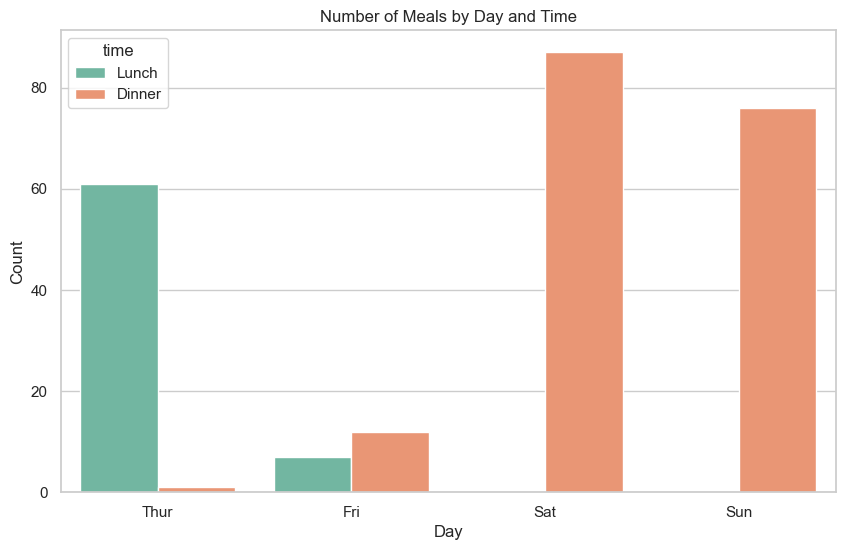

In [8]:
# Count plot
plt.figure(figsize=(10, 6))
sns.countplot(data=tips, x='day', hue='time', palette='Set2')

plt.title('Number of Meals by Day and Time')
plt.xlabel('Day')
plt.ylabel('Count')

plt.show()

### 3.2 Bar Plot (with Error Bars)

**When to use:** Compare means across categories with confidence intervals.

**The black lines (error bars) show uncertainty in the mean.**

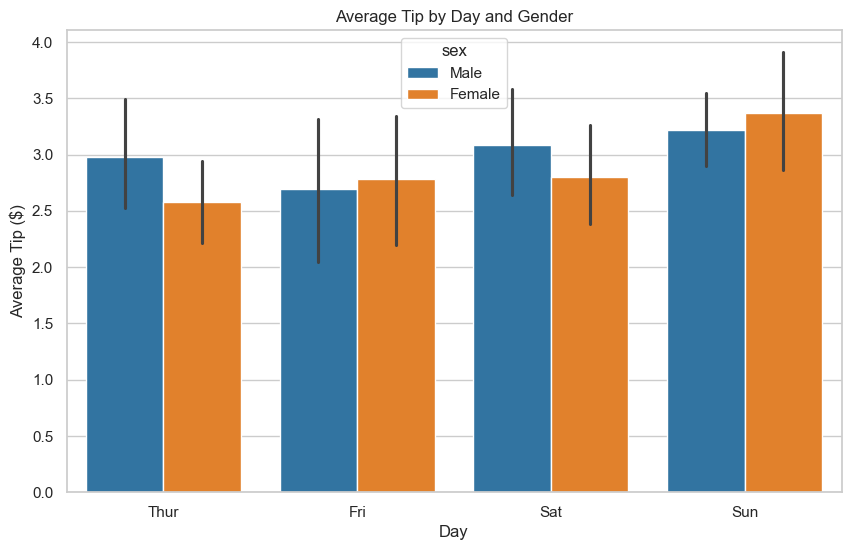

In [9]:
# Bar plot showing mean tip by day
plt.figure(figsize=(10, 6))
sns.barplot(data=tips, x='day', y='tip', hue='sex', errorbar='ci')

plt.title('Average Tip by Day and Gender')
plt.xlabel('Day')
plt.ylabel('Average Tip ($)')

plt.show()

### How to Interpret Error Bars

| Error Bar Overlap | Interpretation |
|-------------------|----------------|
| **No overlap** | Likely a real difference between groups |
| **Slight overlap** | Difference might be significant |
| **Large overlap** | Difference is probably not significant |

### 3.3 Strip and Swarm Plots

**When to use:** Show individual data points by category.

- **Strip plot:** Points may overlap
- **Swarm plot:** Points spread out to avoid overlap

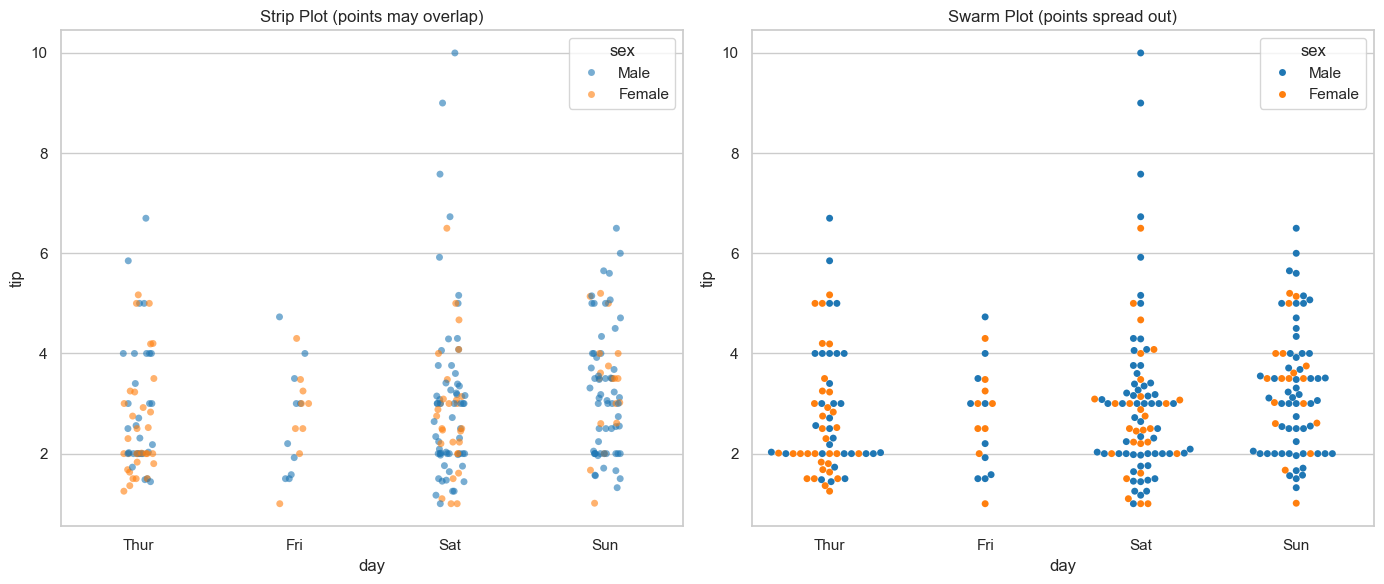

In [10]:
# Strip vs Swarm
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.stripplot(data=tips, x='day', y='tip', hue='sex', ax=axes[0], alpha=0.6)
axes[0].set_title('Strip Plot (points may overlap)')

sns.swarmplot(data=tips, x='day', y='tip', hue='sex', ax=axes[1])
axes[1].set_title('Swarm Plot (points spread out)')

plt.tight_layout()
plt.show()

### Combining Box Plot with Strip Plot

A powerful technique: show both distribution summary AND individual points.

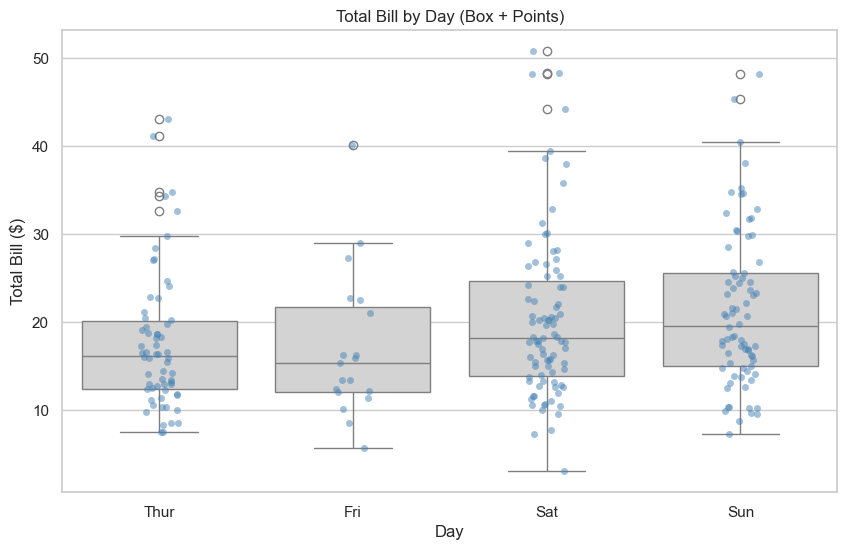

In [11]:
# Box plot + strip plot overlay
plt.figure(figsize=(10, 6))

sns.boxplot(data=tips, x='day', y='total_bill', color='lightgray')
sns.stripplot(data=tips, x='day', y='total_bill', color='steelblue', alpha=0.5)

plt.title('Total Bill by Day (Box + Points)')
plt.xlabel('Day')
plt.ylabel('Total Bill ($)')

plt.show()

---

## 4. Relationship Plots

**Purpose:** Explore relationships between two or more variables.

### 4.1 Scatter Plot with Categories

Use `hue`, `size`, and `style` to add dimensions.

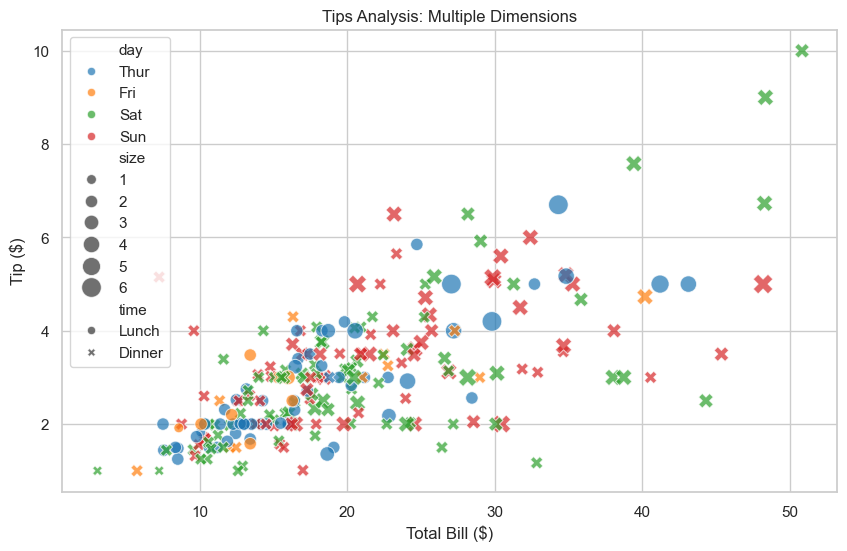

In [12]:
# Enhanced scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=tips, x='total_bill', y='tip', 
                hue='day', size='size', style='time',
                sizes=(50, 200), alpha=0.7)

plt.title('Tips Analysis: Multiple Dimensions')
plt.xlabel('Total Bill ($)')
plt.ylabel('Tip ($)')

plt.show()

### 4.2 Regression Plot

**When to use:** Show the linear relationship between two variables.

**The shaded area shows the 95% confidence interval for the regression line.**

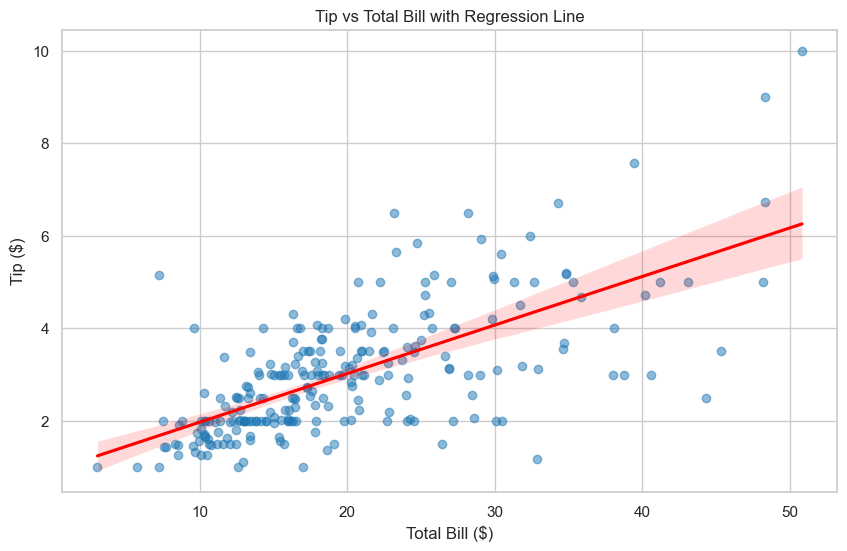

In [13]:
# Regression plot
plt.figure(figsize=(10, 6))
sns.regplot(data=tips, x='total_bill', y='tip', 
            scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})

plt.title('Tip vs Total Bill with Regression Line')
plt.xlabel('Total Bill ($)')
plt.ylabel('Tip ($)')

plt.show()

### Multiple Regression Lines by Category

<Figure size 1000x600 with 0 Axes>

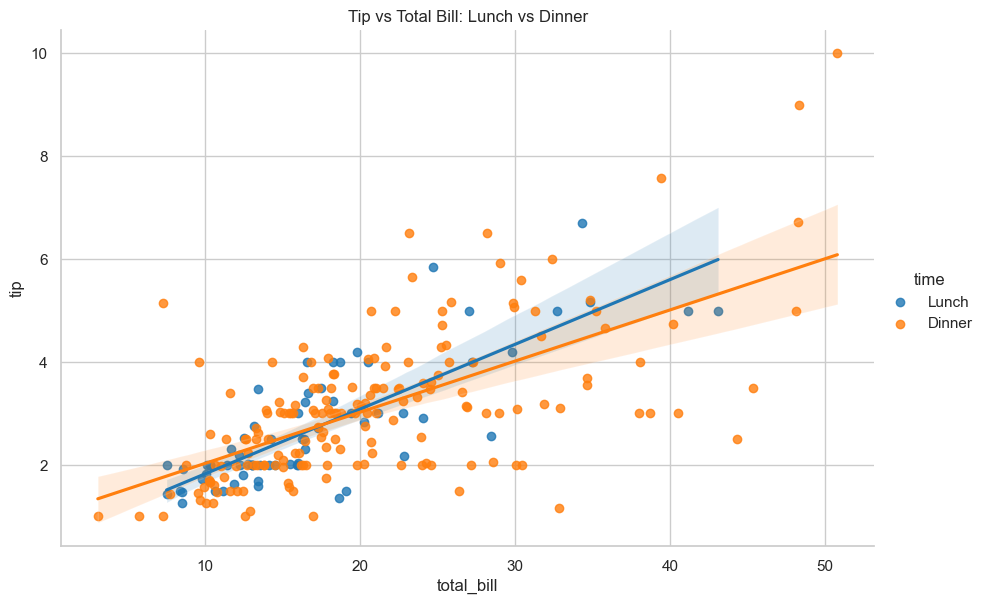

In [14]:
# Regression by category
plt.figure(figsize=(10, 6))
sns.lmplot(data=tips, x='total_bill', y='tip', hue='time', 
           height=6, aspect=1.5)

plt.title('Tip vs Total Bill: Lunch vs Dinner')

plt.show()

### How to Interpret Regression Plots

| Feature | Interpretation |
|---------|----------------|
| **Steep line** | Strong relationship |
| **Flat line** | Weak/no relationship |
| **Narrow confidence band** | Relationship is reliable |
| **Wide confidence band** | More uncertainty |
| **Points close to line** | Strong fit (high R²) |
| **Points far from line** | Weak fit (low R²) |

### 4.3 Correlation Heatmap

**When to use:** See correlations between all numeric variables at once.

**Correlation values:**
- **+1:** Perfect positive correlation
- **0:** No correlation
- **-1:** Perfect negative correlation

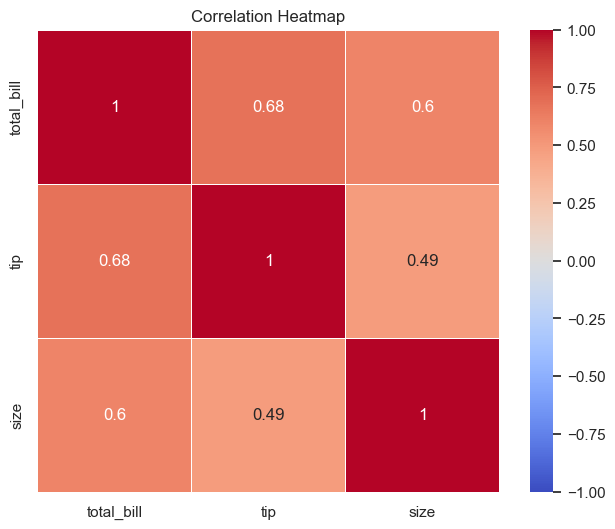

In [15]:
# Calculate correlation matrix
correlation_matrix = tips.select_dtypes(include=[np.number]).corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', 
            vmin=-1, vmax=1, center=0, 
            square=True, linewidths=0.5)

plt.title('Correlation Heatmap')

plt.show()

### How to Interpret Correlation Heatmaps

| Color | Correlation | Meaning |
|-------|-------------|----------|
| **Dark red** | Strong positive (+0.7 to +1) | Variables increase together |
| **Light/White** | No correlation (-0.3 to +0.3) | No linear relationship |
| **Dark blue** | Strong negative (-0.7 to -1) | One increases, other decreases |

**Watch out for:**
- Diagonal is always 1 (variable correlated with itself)
- Matrix is symmetric (same values above/below diagonal)

---

## 5. Multi-Plot Grids

**Purpose:** Create multiple related plots in one figure.

### 5.1 Pair Plot

**When to use:** Explore relationships between ALL pairs of numeric variables.

**Perfect for initial data exploration!**

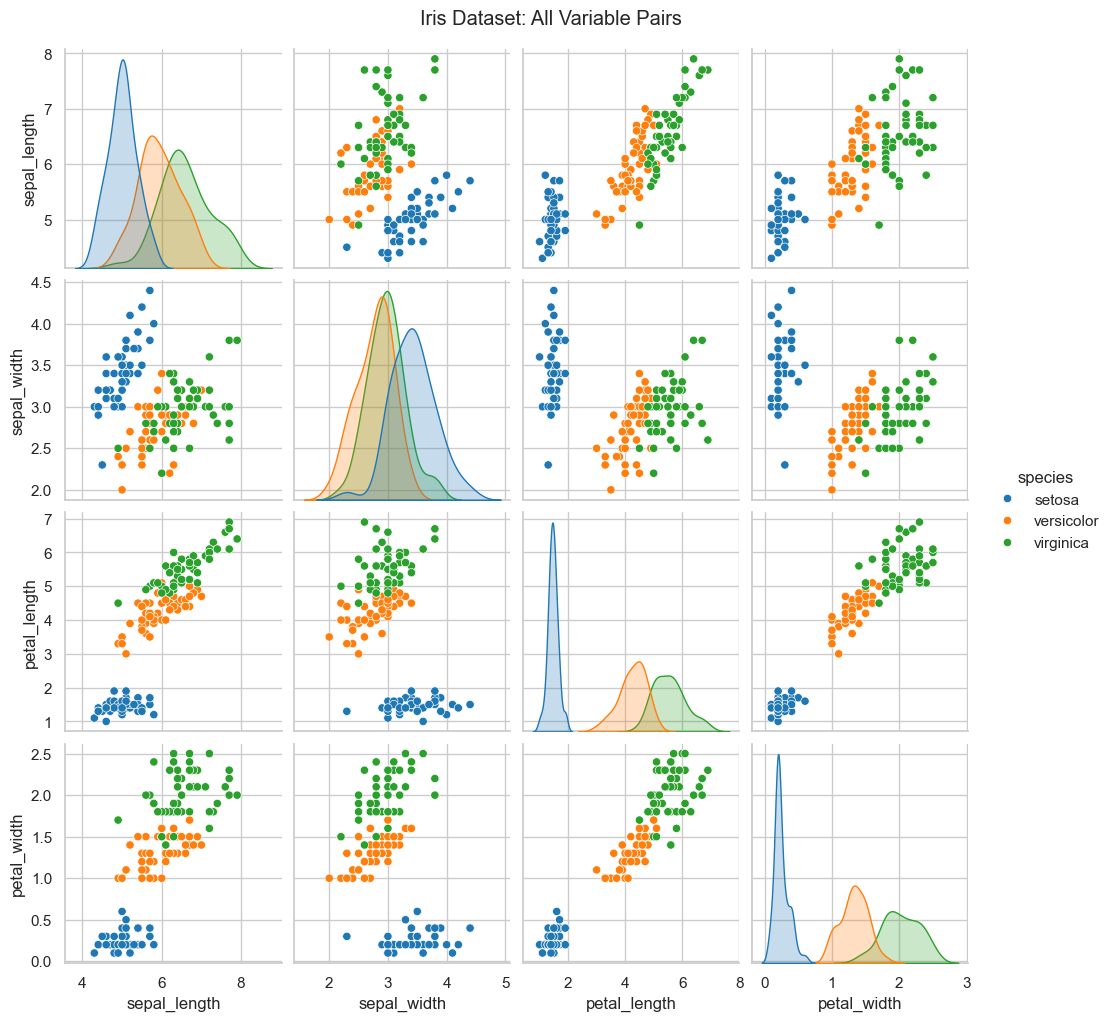

In [16]:
# Pair plot for iris dataset
sns.pairplot(iris, hue='species', height=2.5)

plt.suptitle('Iris Dataset: All Variable Pairs', y=1.02)
plt.show()

### How to Read a Pair Plot

- **Diagonal:** Distribution of each variable (by category if `hue` is set)
- **Off-diagonal:** Scatter plots of variable pairs
- **Look for:** Clusters, linear relationships, outliers

### 5.2 FacetGrid

**When to use:** Create a grid of plots, one for each category combination.

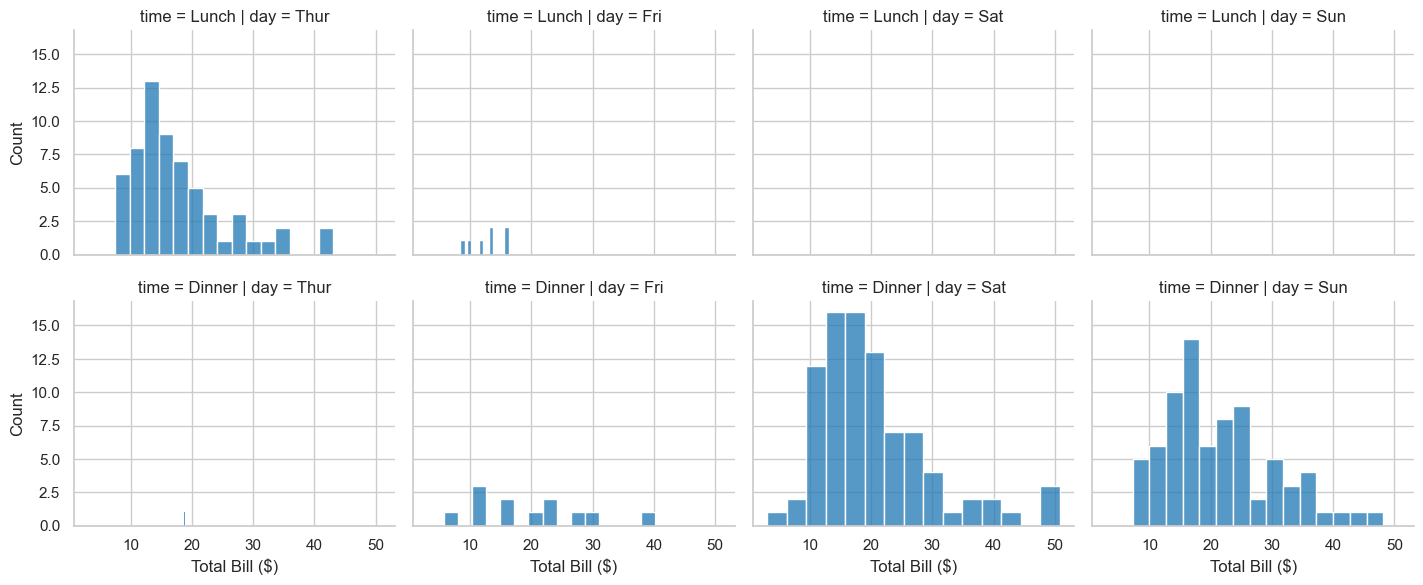

In [17]:
# FacetGrid: Histograms by day and time
g = sns.FacetGrid(tips, col='day', row='time', height=3, aspect=1.2)
g.map(sns.histplot, 'total_bill', bins=15)
g.set_axis_labels('Total Bill ($)', 'Count')

plt.show()

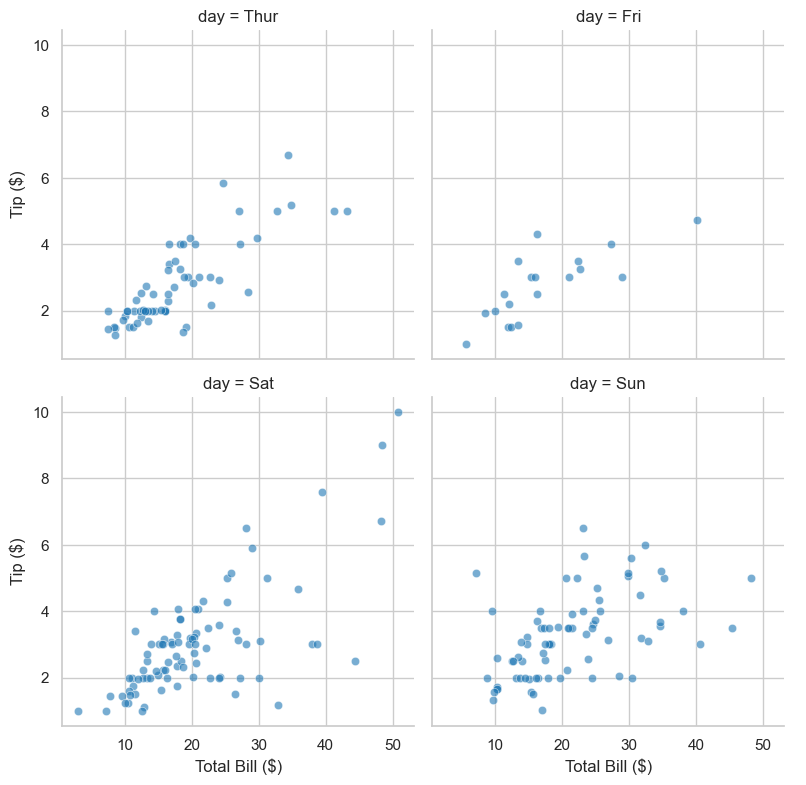

In [18]:
# FacetGrid: Scatter plots by day
g = sns.FacetGrid(tips, col='day', col_wrap=2, height=4)
g.map(sns.scatterplot, 'total_bill', 'tip', alpha=0.6)
g.set_axis_labels('Total Bill ($)', 'Tip ($)')
g.add_legend()

plt.show()

---

## 6. Seaborn Styling

### Built-in Styles

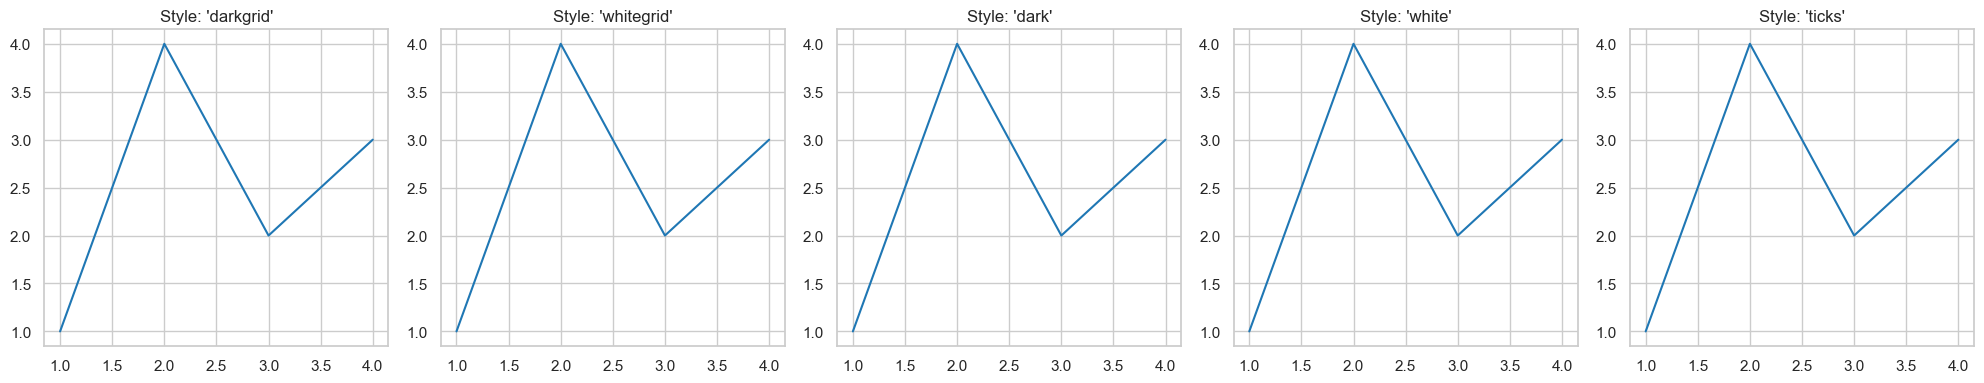

In [19]:
# Different Seaborn styles
styles = ['darkgrid', 'whitegrid', 'dark', 'white', 'ticks']

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, style in zip(axes, styles):
    sns.set_style(style)
    sns.lineplot(x=[1, 2, 3, 4], y=[1, 4, 2, 3], ax=ax)
    ax.set_title(f"Style: '{style}'")

plt.tight_layout()
plt.show()

# Reset to default
sns.set_style('whitegrid')

### Color Palettes

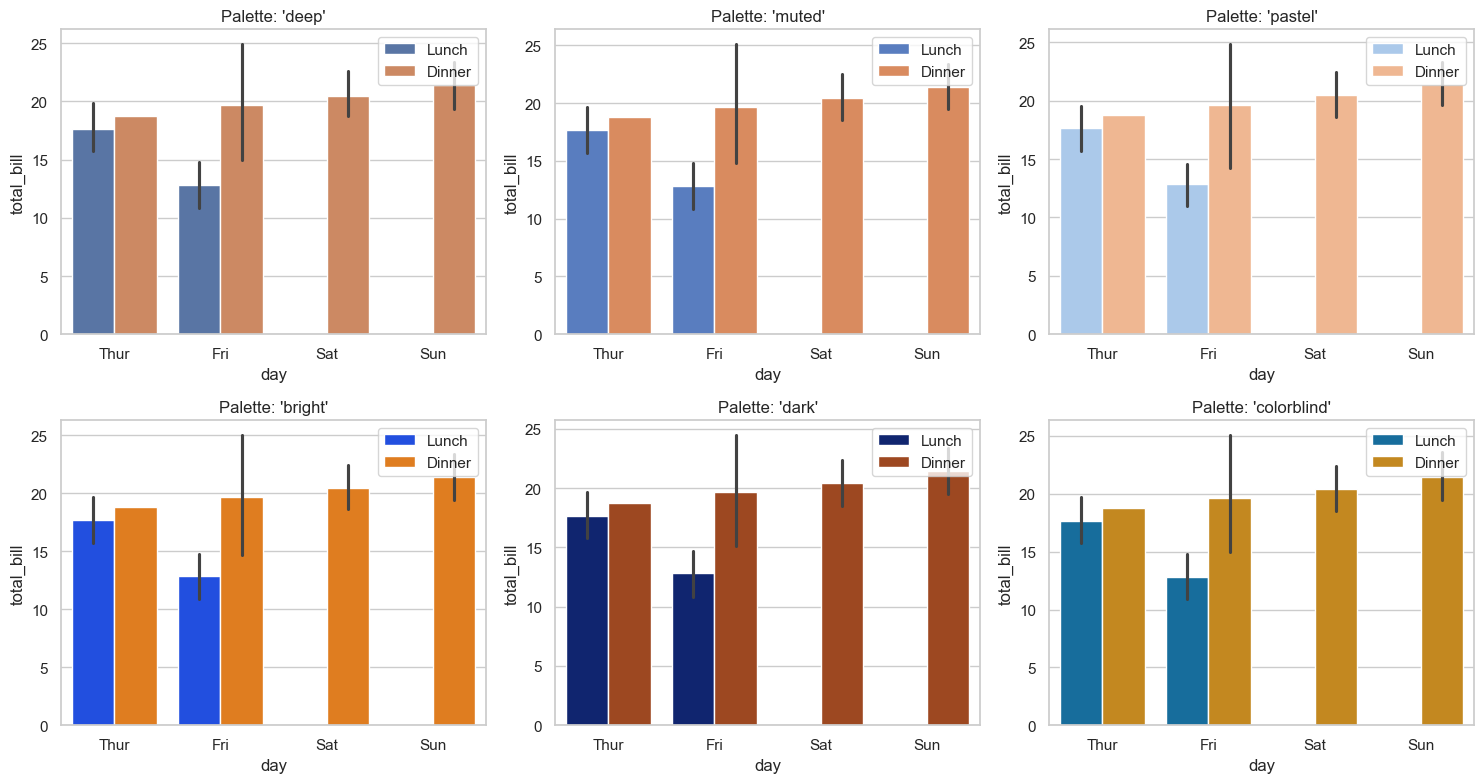

In [20]:
# Show available color palettes
palettes = ['deep', 'muted', 'pastel', 'bright', 'dark', 'colorblind']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for ax, palette in zip(axes, palettes):
    sns.barplot(data=tips, x='day', y='total_bill', 
                hue='time', palette=palette, ax=ax)
    ax.set_title(f"Palette: '{palette}'")
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

**Tip:** Use `'colorblind'` palette for accessibility!

---

## 7. Interpretation Cheat Sheet

### Distribution Plots

| Pattern | What It Means |
|---------|---------------|
| **Symmetric (bell)** | Normal distribution |
| **Right tail** | Positive skew (outliers high) |
| **Left tail** | Negative skew (outliers low) |
| **Two humps** | Bimodal (two groups) |

### Box Plots

| Pattern | What It Means |
|---------|---------------|
| **Tall box** | High variability |
| **Short box** | Low variability |
| **Many dots** | Many outliers |
| **Median off-center** | Skewed distribution |

### Scatter/Regression

| Pattern | What It Means |
|---------|---------------|
| **Upward trend** | Positive correlation |
| **Downward trend** | Negative correlation |
| **No trend** | No linear relationship |
| **Clusters** | Subgroups exist |

### Heatmaps

| Pattern | What It Means |
|---------|---------------|
| **Dark cluster** | Correlated variables |
| **Checkerboard** | Mixed relationships |
| **All light** | Variables are independent |

---

## Summary

In this notebook, you learned:

1. **Why Seaborn?** - Beautiful defaults, statistical focus, less code
2. **Distribution plots:**
   - `histplot()` - Histogram with optional KDE
   - `boxplot()` - Summary statistics + outliers
   - `violinplot()` - Full distribution shape
3. **Categorical plots:**
   - `countplot()` - Count by category
   - `barplot()` - Mean with error bars
   - `stripplot()` / `swarmplot()` - Individual points
4. **Relationship plots:**
   - `scatterplot()` - Multi-dimensional with hue/size/style
   - `regplot()` / `lmplot()` - With regression line
   - `heatmap()` - Correlation matrix
5. **Multi-plot grids:**
   - `pairplot()` - All variable pairs
   - `FacetGrid` - Grid by categories

**Next:** Continue to `01c_Advanced_Interactive.ipynb` for advanced Matplotlib and Plotly.

---

## Practice Exercises

Complete these exercises, then try `01b_Seaborn_Exercise.ipynb`.

### Exercise 1: Distribution Analysis

Create a violin plot comparing tip amounts by day of the week. Color by smoker status.

In [21]:
# Your code here


### Exercise 2: Correlation Analysis

Using the iris dataset, create a correlation heatmap for all numeric variables.

In [22]:
# Your code here


### Exercise 3: FacetGrid

Create a FacetGrid showing the relationship between total_bill and tip, with separate plots for each day.

In [23]:
# Your code here
